# 01 · Who wins on Sunday? Baselines and logistic regression

**Goal:** for every driver in a race, estimate the chance they win, after qualifying and before the start.

**What you'll learn**
1. Why "accuracy" can be a trap with rare events
2. Splitting data **by time**, not at random
3. Scoring predictions **race by race**
4. Building **baselines** that a model has to beat
5. A **logistic regression** pipeline, and reading what it learned
6. **Calibration**: does "30%" really mean 30%?

Data: `ml_driver_race_modern` from the warehouse: 2014 onwards, one row per driver per race, drivers who started.

In [1]:
import sqlite3
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

DB = next(p for p in [Path("../data/warehouse.db"), Path("data/warehouse.db")] if p.exists())
with sqlite3.connect(DB) as con:
    df = pd.read_sql("SELECT * FROM ml_driver_race_modern", con)

print(f"{len(df):,} rows · {df['race_key'].nunique()} races · seasons {df.season.min()}-{df.season.max()}")
df[["season", "round", "driver_ref", "constructor_ref", "grid", "quali_gap_pct",
    "pre_drv_last5_avg_pts", "pre_con_last5_avg_pts", "target_win"]].head()

4,962 rows · 245 races · seasons 2014-2026


,season,round,driver_ref,constructor_ref,grid,quali_gap_pct,pre_drv_last5_avg_pts,pre_con_last5_avg_pts,target_win
0,2014,1,rosberg,mercedes,3.0,1.971,9.8,7.7,1
1,2014,1,kevin_magnussen,mclaren,4.0,0.192,NaN,4.1,0
2,2014,1,button,mclaren,10.0,0.684,3.0,4.1,0
3,2014,1,alonso,ferrari,5.0,0.675,9.4,7.0,0
4,2014,1,bottas,williams,15.0,0.910,0.8,0.4,0


## 1 · The accuracy trap

Only one driver in each race wins, so about 1 row in 20 is a win. A "model" that **always answers 'no'** is right on about 95% of rows and tells you nothing. With rare events, row-level accuracy is the wrong measure.

In [2]:
win_rate = df["target_win"].mean()
print(f"Rows that are a win:                 {win_rate:.1%}")
print(f"Accuracy of always answering 'no':   {1 - win_rate:.1%}  <- impressive-looking and useless")

Rows that are a win:                 4.9%
Accuracy of always answering 'no':   95.1%  <- impressive-looking and useless


## 2 · Split by time, not at random

A random split would put races from 2023 in training and races from 2021 in testing, so the model would learn from the future. Real forecasting only ever has the past, so we test on seasons the model has never seen:

| Part | Seasons | Purpose |
|---|---|---|
| train | 2014–2021 | the model learns here |
| test | 2022–2024 | honest score: new car rules arrived in 2022 |
| 2026 | 2026 | bonus check: another rule reset (2025 is missing from the data) |

In [3]:
train = df[df.season.between(2014, 2021)].copy()
test = df[df.season.between(2022, 2024)].copy()
new_rules = df[df.season == 2026].copy()

for name, part in [("train", train), ("test", test), ("2026", new_rules)]:
    print(f"{name:<6} {part.season.min()}-{part.season.max()}  {part['race_key'].nunique():>3} races  {len(part):>5,} rows")

train  2014-2021  160 races  3,244 rows
test   2022-2024   68 races  1,351 rows
2026   2026-2026   17 races    367 rows


## 3 · Scoring race by race

Every race has exactly one winner, so we first rescale each race's probabilities to add up to 100%, then measure:

- **favourite won**: how often the model's top pick won
- **winner in top 3**: how often the winner was among its top three picks
- **log loss**: on average, how surprised the model was by the real winner (−log of the probability it gave them). Lower is better. Pure guessing among ~20 drivers scores about log(20) ≈ 3.0. Log loss rewards honest probabilities, not just the right pick.

> **A leak hiding in the row order.** The warehouse stores each race sorted by finishing position, so the winner is always the first row. If two drivers get the same probability, sorting keeps their original order, and the scorer quietly "picks" the real winner. The first version of this notebook fell into exactly this trap: the everyone-is-equal guess scored a perfect 100%. The fix is to **break ties at random**, with a fresh random number for every row. A result that looks too good to be true usually is.

In [4]:
def evaluate(part, prob_col, label):
    # Score win probabilities race by race (each race has exactly one winner).
    part = part.assign(p=part[prob_col] / part.groupby("race_key")[prob_col].transform("sum"))
    rng = np.random.default_rng(0)
    scores = []
    for _, race in part.groupby("race_key"):
        winner = race[race.target_win == 1]
        if len(winner) != 1:
            continue
        # break ties at random: rows are stored in finishing order, so ties must never fall back on it
        ranked = race.assign(tie=rng.random(len(race))).sort_values(["p", "tie"], ascending=False)
        scores.append({
            "hit": ranked.iloc[0].target_win == 1,
            "top3": winner.index[0] in ranked.index[:3],
            "logloss": -np.log(max(winner.p.iloc[0], 1e-6)),
        })
    s = pd.DataFrame(scores)
    return pd.Series({"favourite won": s.hit.mean(), "winner in top 3": s.top3.mean(),
                      "log loss": s.logloss.mean(), "races": len(s)}, name=label)

## 4 · Baselines: the bar a model has to clear

- **Guess**: everyone is equally likely.
- **Grid slot**: how often each starting position won during the training years. Pole won about half the time, so this is already a strong predictor.

If a model can't beat these, it isn't adding anything.

In [5]:
def grid_slot(part):
    return part["grid"].fillna(21).clip(upper=21)        # pit-lane starts count as the back of the grid

train_slots = train.assign(slot=grid_slot(train))
win_by_grid = train_slots.groupby("slot")["target_win"].agg(["sum", "count"])
win_by_grid["win_rate"] = (win_by_grid["sum"] + 0.1) / (win_by_grid["count"] + 2)  # smoothing: no slot is exactly 0%

for part in (test, new_rules):
    part["p_guess"] = 1.0
    part["p_grid"] = grid_slot(part).map(win_by_grid["win_rate"]).fillna(win_by_grid["win_rate"].min())

win_by_grid["win_rate"].head(6).map("{:.1%}".format).rename("win rate by grid slot, 2014-2021")

slot
1.0    52.2%
2.0    24.9%
3.0    10.6%
4.0     3.8%
5.0     1.9%
6.0     3.1%
Name: win rate by grid slot, 2014-2021, dtype: object

## 5 · Logistic regression

Logistic regression outputs a probability between 0 and 1 for a yes/no question ("does this driver win?"). It learns one **weight per feature**.

Features (all known before the race starts):

| Feature | Meaning |
|---|---|
| `log_grid` | starting position, log-scaled: P1 vs P2 matters far more than P15 vs P16 |
| `quali_gap_pct` | % slower than pole in qualifying |
| `pre_drv_last5_avg_pts` | the driver's points per race over the last 5 races |
| `pre_con_last5_avg_pts` | the car's points per entry over the last 5 races |
| `pre_drv_last3_pace_gap_pct` | the driver's race pace vs the quickest, last 3 races |
| `pre_con_last3_pace_gap_pct` | the same for the car |
| `pre_drv_last10_dnf_rate` | share of the last 10 races that ended in a DNF |

A **pipeline** chains three steps:
1. **impute**: fill missing values with the median
2. **scale**: put every feature on the same scale, so the weights are comparable
3. **model**

Each step is **fitted on the training data only**. Taking the median or the scale from the test seasons would leak information about them, a subtle form of leakage.

In [6]:
FEATURES = ["log_grid", "quali_gap_pct", "pre_drv_last5_avg_pts", "pre_con_last5_avg_pts",
            "pre_drv_last3_pace_gap_pct", "pre_con_last3_pace_gap_pct", "pre_drv_last10_dnf_rate"]

for part in (train, test, new_rules):
    part["log_grid"] = np.log(grid_slot(part))

def make_model():
    return make_pipeline(SimpleImputer(strategy="median"), StandardScaler(), LogisticRegression(max_iter=1000))

grid_only = make_model().fit(train[["log_grid"]], train["target_win"])
full = make_model().fit(train[FEATURES], train["target_win"])

for part in (test, new_rules):
    part["p_lr_grid"] = grid_only.predict_proba(part[["log_grid"]])[:, 1]
    part["p_lr_full"] = full.predict_proba(part[FEATURES])[:, 1]
print("trained on", len(train), "rows")

trained on 3244 rows


## 6 · Results on the unseen 2022–2024 seasons

In [7]:
fmt = {"favourite won": "{:.0%}", "winner in top 3": "{:.0%}", "log loss": "{:.3f}", "races": "{:.0f}"}
results = pd.DataFrame([
    evaluate(test, "p_guess", "Guess (everyone equal)"),
    evaluate(test, "p_grid", "Baseline: win rate by grid slot"),
    evaluate(test, "p_lr_grid", "Logistic regression: grid only"),
    evaluate(test, "p_lr_full", "Logistic regression: grid + form + car"),
])
results.style.format(fmt)

,favourite won,winner in top 3,log loss,races
Guess (everyone equal),1%,9%,2.989,68
Baseline: win rate by grid slot,51%,84%,1.635,68
Logistic regression: grid only,51%,84%,1.600,68
Logistic regression: grid + form + car,54%,91%,1.243,68


## 7 · What did the model learn?

Because every feature was scaled the same way, the weights can be compared. A longer bar means a bigger effect on the win chance: green raises it, red lowers it.

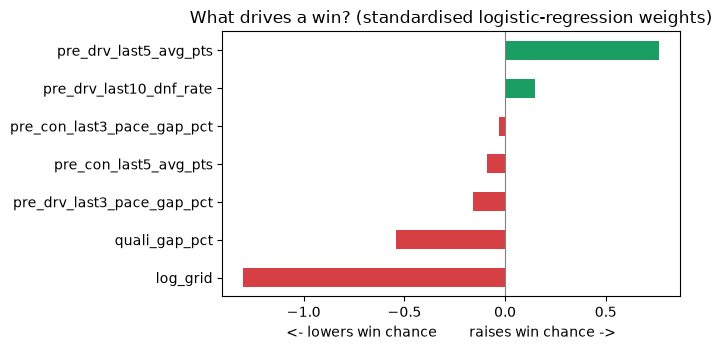

log_grid                     -1.30
quali_gap_pct                -0.54
pre_drv_last3_pace_gap_pct   -0.16
pre_con_last5_avg_pts        -0.09
pre_con_last3_pace_gap_pct   -0.03
pre_drv_last10_dnf_rate       0.15
pre_drv_last5_avg_pts         0.77
dtype: float64

In [8]:
weights = pd.Series(full[-1].coef_[0], index=FEATURES).sort_values()
ax = weights.plot.barh(figsize=(7, 3.6), color=["#d64045" if w < 0 else "#1a9e63" for w in weights])
ax.axvline(0, color="grey", lw=0.8)
ax.set_title("What drives a win? (standardised logistic-regression weights)")
ax.set_xlabel("<- lowers win chance        raises win chance ->")
plt.tight_layout()
plt.show()
weights.round(2)

## 8 · Calibration: does "30%" mean 30%?

We group the test predictions by how confident they were and compare that with how often those drivers actually won. A well-calibrated model sits on the diagonal.

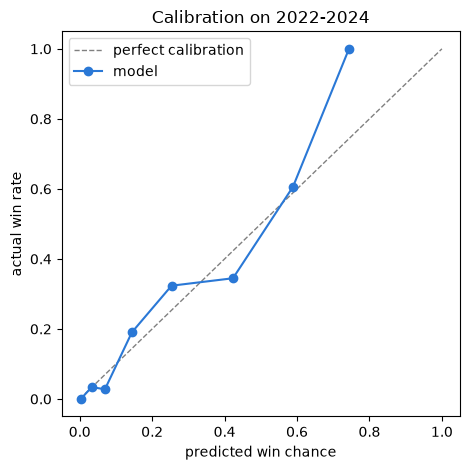

,predicted,actual,drivers
bin,,,
"(-0.001, 0.02]",0.4%,0.1%,994
"(0.02, 0.05]",3.3%,3.4%,118
"(0.05, 0.1]",7.0%,2.8%,72
"(0.1, 0.2]",14.4%,19.0%,63
"(0.2, 0.35]",25.4%,32.4%,34
"(0.35, 0.5]",42.3%,34.5%,29
"(0.5, 0.7]",58.9%,60.6%,33
"(0.7, 1.0]",74.3%,100.0%,8


In [9]:
p = test["p_lr_full"] / test.groupby("race_key")["p_lr_full"].transform("sum")
bins = pd.cut(p, [0, 0.02, 0.05, 0.1, 0.2, 0.35, 0.5, 0.7, 1.0], include_lowest=True)
calib = test.assign(p=p, bin=bins).groupby("bin", observed=True).agg(
    predicted=("p", "mean"), actual=("target_win", "mean"), drivers=("p", "size"))

fig, ax = plt.subplots(figsize=(4.8, 4.8))
ax.plot([0, 1], [0, 1], ls="--", color="grey", lw=1, label="perfect calibration")
ax.plot(calib.predicted, calib.actual, marker="o", color="#2a78d6", label="model")
ax.set_xlabel("predicted win chance")
ax.set_ylabel("actual win rate")
ax.set_title("Calibration on 2022-2024")
ax.legend()
plt.tight_layout()
plt.show()
calib.style.format({"predicted": "{:.1%}", "actual": "{:.1%}"})

## 9 · Bonus: 2026, a season under brand-new rules

The model never saw 2026. Its "form" features see the 2026 pecking order as it unfolds, but its weights were learned in 2014–2021.

In [10]:
pd.DataFrame([
    evaluate(new_rules, "p_grid", "Baseline: win rate by grid slot"),
    evaluate(new_rules, "p_lr_full", "Logistic regression: grid + form + car"),
]).style.format(fmt)

,favourite won,winner in top 3,log loss,races
Baseline: win rate by grid slot,71%,94%,1.221,17
Logistic regression: grid + form + car,71%,94%,1.085,17


In [11]:
race = new_rules[new_rules["round"] == 17].copy()      # Singapore
race["win chance"] = race["p_lr_full"] / race["p_lr_full"].sum()
(race.sort_values("win chance", ascending=False)
     [["driver_ref", "constructor_ref", "grid", "win chance", "target_position"]]
     .head(6).style.format({"win chance": "{:.1%}", "grid": "{:.0f}"}))

,driver_ref,constructor_ref,grid,win chance,target_position
4940,max_verstappen,red_bull,1,55.2%,1.000000
4941,leclerc,ferrari,2,15.0%,2.000000
4942,antonelli,mercedes,4,14.3%,3.000000
4945,hamilton,ferrari,3,6.8%,6.000000
4943,norris,mclaren,5,3.7%,4.000000
4944,piastri,mclaren,6,1.4%,5.000000


## 10 · Takeaways

Results from the first run (your numbers may differ slightly if the data changes):

| 2022–2024 test | favourite won | winner in top 3 | log loss |
|---|---|---|---|
| Guess | ~5% (noisy) | ~15% (noisy) | 2.99 |
| Grid-slot baseline | 52% | 84% | 1.64 |
| LR, grid only | 52% | 84% | 1.60 |
| **LR, grid + form + car** | **54%** | **91%** | **1.24** |

1. **The baseline is tough.** Pole won about half the races, so "the pole-sitter wins" gets most of the way. Always measure your model against a simple rule before trusting it.
2. **The algorithm alone added almost nothing.** Logistic regression on the grid alone ties the lookup table. The gains came from **new information** (form, qualifying gap), not from a fancier method.
3. **The pick barely changed, but the probabilities did.** "Favourite won" only rose from 52% to 54%, because the pole-sitter is usually still the favourite. Log loss fell from 1.64 to 1.24, and the winner landed in the top 3 far more often. The model knows *when* pole is a safe bet and when it isn't. That's why the main score is log loss, not "accuracy".
4. **Weights aren't causes.** The car's form got a small *negative* weight, and the DNF rate a *positive* one. A fast car doesn't hurt and retiring doesn't help. Once points-based form is in the model, a driver who scored well *despite* some DNFs must have been very quick when they finished, and driver form and car form move together, so the model credits one of them. When features overlap like this (*collinearity*), read the weights as a group.
5. **Seasons differ a lot.** Split by season, the favourite won 77% of 2023's races (one dominant car) and 36% of 2022's. Averages over a few dozen races are noisy.
6. **2026 under new rules:** the model kept its edge (log loss 1.09 vs 1.22 for the baseline) over only 17 races, and 2025 is missing, so the "last 5 races" features jump straight from 2024.
7. **Calibration is decent, not perfect.** Look at where the blue line leaves the diagonal, and how few drivers sit in the highest-confidence bins.

## 11 · Try it yourself

1. **Before qualifying:** remove `log_grid` and `quali_gap_pct` from `FEATURES`. How much worse does log loss get? That's what qualifying is worth.
2. **More features:** add `pre_drv_circuit_avg_pos` or `pre_drv_champ_pts`. Does the test log loss improve, or is it just noise?
3. **Regularisation:** try `LogisticRegression(C=0.05, max_iter=1000)`. How do the weights in section 7 change?
4. **Less history:** train on 2018–2021 only. Do older seasons help or hurt?
5. **Upsets:** list the test races where the favourite had over 60% and still lost. What does `target_status_category` say happened?

**Next notebook:** this model scores each driver *separately*, then rescales so each race adds up to 100%. **Plackett–Luce** models the whole finishing order at once: who wins, then who's best of the rest, and so on. It's the model the season simulator really needs.